# Tests for the kernel-based Koopman optimal control codes

## Part 1. `dynamics.py`: input-affine systems

We test `InputAffineSystem` on a non-isothermal CSTR with an exothermic reaction $A \to B$:

$$
\begin{aligned}
\dot C_A &= -k_0 e^{-E/(R T)} C_A + \frac{F}{V}\,(C_{A0} - C_A), \\
\dot T   &= \frac{-\Delta H}{\rho c_p} k_0 e^{-E/(R T)} C_A + \frac{F}{V}\,(T_0 - T) + \frac{Q}{\rho c_p V}.
\end{aligned}
$$

The state is $x = (C_A, T)$ and the input is $u = (F, Q)$: the feed flow rate and the heat duty.
The system has the input-affine form $\dot x = f_0(x) + f_1(x) u_1 + f_2(x) u_2$ with

- $f_0(x)$: the reaction terms (a batch reactor),
- $f_1(x) = \big((C_{A0}-C_A)/V,\ (T_0-T)/V\big)$, which depends on the state,
- $f_2(x) = \big(0,\ 1/(\rho c_p V)\big)$, a constant field.

The variables have very different magnitudes ($C_A \sim 1$, $T \sim 400$, $Q \sim 10^4$), so the example also exercises the scaling options.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from dynamics import InputAffineSystem

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=5, suppress=False)

### 1.1 Define the system  — requirement (1)

In [2]:
# CSTR parameters (time in h, concentration in kmol/m^3, temperature in K, Q in kJ/h)
V, k0, E, Rg = 1.0, 8.46e6, 5.0e4, 8.314
dH, rho, cp  = -1.15e4, 1000.0, 0.231
T0, CA0      = 300.0, 4.0

def f0(x):
    CA, T = x
    r = k0 * np.exp(-E / (Rg * T)) * CA
    return np.array([-r, -dH / (rho * cp) * r])

def f1(x):                      # feed flow rate F
    CA, T = x
    return np.array([(CA0 - CA) / V, (T0 - T) / V])

def f2(x):                      # heat duty Q
    return np.array([0.0, 1.0 / (rho * cp * V)])

# The input fields can be given as a list [f1, f2] or as one callable g(x) -> (n, m).
cstr = InputAffineSystem(f0, [f1, f2], n_states=2, n_inputs=2, name="CSTR",
                         x_test=[2.0, 400.0])   # f0 is singular at T = 0
print(cstr)

# Check: the same system defined through a matrix-valued g(x) gives identical evaluations.
cstr_G = InputAffineSystem(f0, lambda x: np.column_stack([f1(x), f2(x)]), 2, 2,
                           x_test=[2.0, 400.0])
x_chk, u_chk = np.array([1.5, 410.0]), np.array([4.0, 1e4])
print("\nrhs (list of f_j)   :", cstr.rhs(x_chk, u_chk))
print("rhs (matrix G(x))   :", cstr_G.rhs(x_chk, u_chk))
print("f_0, f_1, f_2 at x  :", [cstr.vector_field(x_chk, j) for j in range(3)])

System CSTR: n = 2, m = 2

rhs (list of f_j)   : [   4.59055 -127.40809]
rhs (matrix G(x))   : [   4.59055 -127.40809]
f_0, f_1, f_2 at x  : [array([ -5.40945, 269.30187]), array([   2.5, -110. ]), array([0.     , 0.00433])]


### 1.2 Simulating the drift $f_0$ (all inputs zero) — requirement (2)

With $F = Q = 0$ the CSTR is an adiabatic batch reactor. $C_A$ decreases and $T$ rises, and the reaction runs away once the reactor is hot enough.

SimulationResult(mode='drift f_0', t=[0, 2], steps=401, success=True, wall_time=0.0784s)


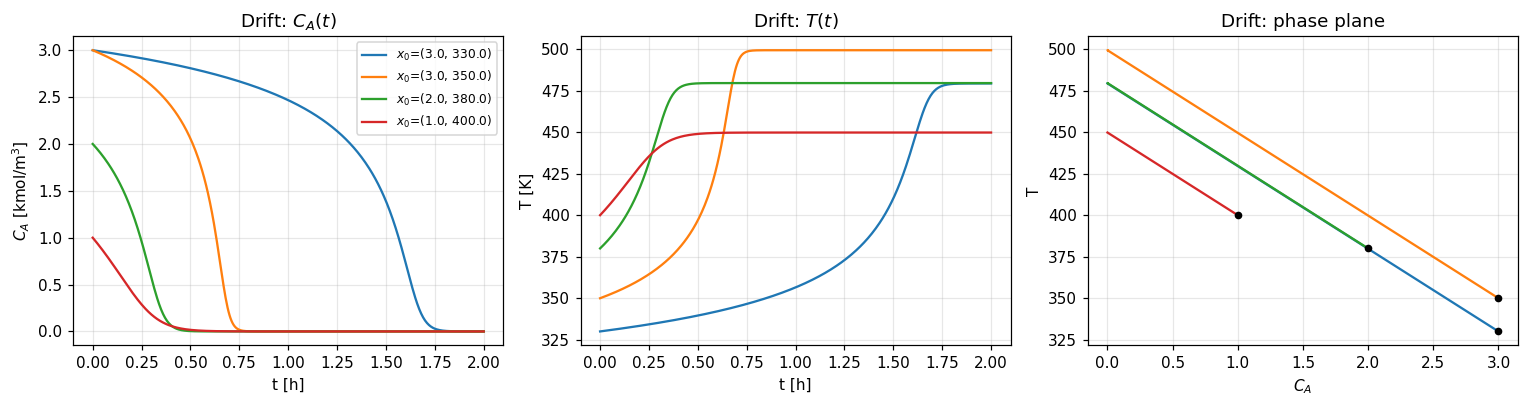

conserved quantity: max deviation = 3.41e-13 K


In [3]:
x0_list = [[3.0, 330.0], [3.0, 350.0], [2.0, 380.0], [1.0, 400.0]]
t_eval  = np.linspace(0.0, 2.0, 401)
drift_runs = [cstr.simulate_drift(x0, (0.0, 2.0), t_eval=t_eval) for x0 in x0_list]
print(drift_runs[0])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for x0, r in zip(x0_list, drift_runs):
    lbl = f"$x_0$=({x0[0]}, {x0[1]})"
    ax[0].plot(r.t, r.x[0], label=lbl)
    ax[1].plot(r.t, r.x[1], label=lbl)
    ax[2].plot(r.x[0], r.x[1], label=lbl)
    ax[2].plot(*r.x[:, 0], "ko", ms=4)
ax[0].set(xlabel="t [h]", ylabel="$C_A$ [kmol/m$^3$]", title="Drift: $C_A(t)$")
ax[1].set(xlabel="t [h]", ylabel="T [K]", title="Drift: $T(t)$")
ax[2].set(xlabel="$C_A$", ylabel="T", title="Drift: phase plane")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Sanity check: in a batch reactor, T + (-dH/(rho cp)) C_A is conserved.
r = drift_runs[0]
inv = r.x[1] + (-dH / (rho * cp)) * r.x[0]
print(f"conserved quantity: max deviation = {np.ptp(inv):.2e} K")

### 1.3 Simulating each input field $f_j$ (unit input on channel $j$, no drift) — requirement (3)

- $\dot x = f_1(x)$ relaxes linearly towards the feed state $(C_{A0}, T_0) = (4, 300)$ with rate $1/V$, along straight lines in the phase plane.
- $\dot x = f_2(x)$ raises $T$ at the constant rate $1/(\rho c_p V)$ and leaves $C_A$ unchanged.

`simulate_input_fields` returns one trajectory for each $j = 1, \dots, m$.

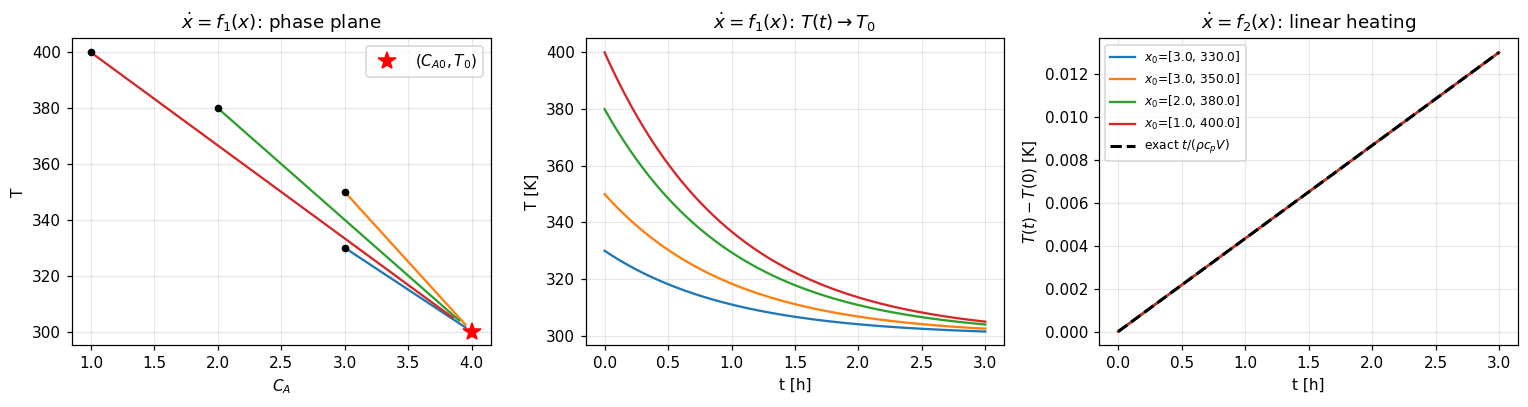

max error, f_1 flow: 1.52e-05
max error, f_2 flow: 3.81e-14


In [4]:
t_eval = np.linspace(0.0, 3.0, 301)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for x0 in x0_list:
    r1, r2 = cstr.simulate_input_fields(x0, (0.0, 3.0), t_eval=t_eval)
    ax[0].plot(r1.x[0], r1.x[1]); ax[0].plot(*r1.x[:, 0], "ko", ms=4)
    ax[1].plot(r1.t, r1.x[1], label=f"T, $x_0$={x0}")
    ax[2].plot(r2.t, r2.x[1] - x0[1], label=f"$x_0$={x0}")
ax[0].plot(CA0, T0, "r*", ms=12, label="$(C_{A0}, T_0)$")
ax[0].set(xlabel="$C_A$", ylabel="T", title="$\\dot x = f_1(x)$: phase plane"); ax[0].legend()
ax[1].set(xlabel="t [h]", ylabel="T [K]", title="$\\dot x = f_1(x)$: $T(t) \\to T_0$")
ax[2].plot(t_eval, t_eval / (rho * cp * V), "k--", lw=2, label="exact $t/(\\rho c_p V)$")
ax[2].set(xlabel="t [h]", ylabel="$T(t) - T(0)$ [K]", title="$\\dot x = f_2(x)$: linear heating")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Accuracy against the closed-form flows
r1, r2 = cstr.simulate_input_fields(x0_list[0], (0.0, 3.0), t_eval=t_eval)
x0 = np.array(x0_list[0]); xf = np.array([CA0, T0])
exact1 = xf[:, None] + (x0 - xf)[:, None] * np.exp(-t_eval / V)
print(f"max error, f_1 flow: {np.max(np.abs(r1.x - exact1)):.2e}")
print(f"max error, f_2 flow: {np.max(np.abs(r2.x[1] - x0[1] - t_eval/(rho*cp*V))):.2e}")

### 1.4 Steady states under a nominal input

At $u_{nom} = (F, Q) = (5,\ 2\times 10^4)$ the CSTR has three steady states. The initial guess decides which one the root finder returns. The middle steady state is open-loop unstable, so we use it as the operating point.

low-T   steady state x = [  3.95511 319.55068],  residual = 8.9e-14
middle  steady state x = [  1.87865 422.9245 ],  residual = 3.4e-13
high-T  steady state x = [3.80114e-01 4.97527e+02],  residual = 0.0e+00


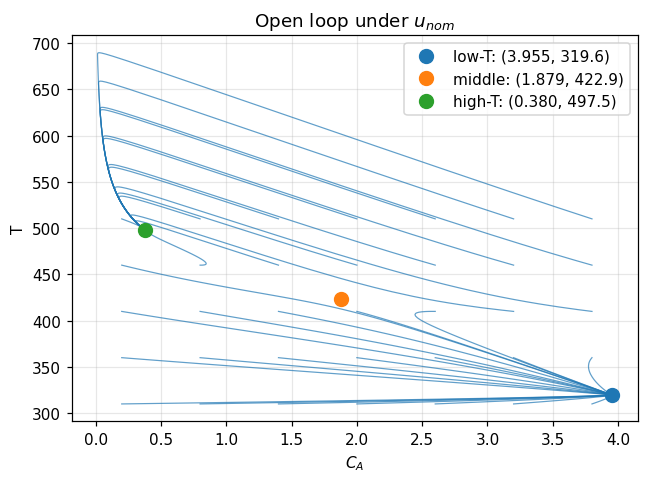

In [5]:
u_nom = np.array([5.0, 2.0e4])
guesses = {"low-T": [3.5, 310.0], "middle": [1.95, 402.0], "high-T": [0.1, 480.0]}
ss = {k: cstr.find_steady_state(u_nom, g) for k, g in guesses.items()}
for k, xs in ss.items():
    print(f"{k:7s} steady state x = {xs},  residual = {np.max(np.abs(cstr.rhs(xs, u_nom))):.1e}")

# Phase portrait under the constant nominal input
fig, ax = plt.subplots(figsize=(6, 4.5))
for CA_i in np.linspace(0.2, 3.8, 7):
    for T_i in (310.0, 360.0, 410.0, 460.0, 510.0):
        r = cstr.simulate([CA_i, T_i], (0.0, 3.0), u=u_nom, solver="LSODA")
        ax.plot(r.x[0], r.x[1], color="tab:blue", lw=0.8, alpha=0.7)
for k, xs in ss.items():
    ax.plot(*xs, "o", ms=9, label=f"{k}: ({xs[0]:.3f}, {xs[1]:.1f})")
ax.set(xlabel="$C_A$", ylabel="T", title="Open loop under $u_{nom}$")
ax.legend(); plt.tight_layout(); plt.show()

### 1.5 A new system in shifted and scaled coordinates, with three scaling options — requirement (4)

`shift_to_steady_state` finds the steady state $x_{nom}$ under $u_{nom}$ and returns a **new** `InputAffineSystem` in the dimensionless coordinates $z = D_x^{-1}(x - x_{nom})$, $v = D_u^{-1}(u - u_{nom})$. The new system's own maps are

$$
\tilde f_0(z) = D_x^{-1}\big[f_0(x) + G(x)\,u_{nom}\big], \qquad \tilde f_j(z) = (D_u)_{jj}\, D_x^{-1} f_j(x), \qquad x = x_{nom} + D_x z .
$$

The original system `cstr` is left unchanged.

| option | call | $D_x$, $D_u$ |
|---|---|---|
| no scaling | `scaling=None` | $I$, $I$ |
| nominal values | `scaling='nominal'` | $\mathrm{diag}|x_{nom}|$, $\mathrm{diag}|u_{nom}|$ |
| user-provided | `scaling=(x_scale, u_scale)` | $\mathrm{diag}(x_{scale})$, $\mathrm{diag}(u_{scale})$ |

**Checks:**

- `cstr` is unchanged.
- The new maps match the formulas above.
- $\tilde f_0(0) = 0$.
- Simulating the new system's drift ($v = 0$) from a perturbation of the origin, then mapping back with `to_original_state`, reproduces the original system under $u_{nom}$.

System CSTR (no scaling): n = 2, m = 2
  x = x_offset + x_scale * z,  x_offset = [  1.87865 422.9245 ],  x_scale = [1. 1.]
  u = u_offset + u_scale * v,  u_offset = [5.e+00 2.e+04],  u_scale = [1. 1.]
  new system is a different object: True
  ||f~_0(0)||_inf = 3.41e-13,  max error of f~_0, G~ vs. formula = 0.0e+00

System CSTR (nominal): n = 2, m = 2
  x = x_offset + x_scale * z,  x_offset = [  1.87865 422.9245 ],  x_scale = [  1.87865 422.9245 ]
  u = u_offset + u_scale * v,  u_offset = [5.e+00 2.e+04],  u_scale = [5.e+00 2.e+04]
  new system is a different object: True
  ||f~_0(0)||_inf = 3.78e-15,  max error of f~_0, G~ vs. formula = 8.9e-16

System CSTR (custom): n = 2, m = 2
  x = x_offset + x_scale * z,  x_offset = [  1.87865 422.9245 ],  x_scale = [ 0.5 20. ]
  u = u_offset + u_scale * v,  u_offset = [5.e+00 2.e+04],  u_scale = [1.e+00 1.e+04]
  new system is a different object: True
  ||f~_0(0)||_inf = 1.71e-14,  max error of f~_0, G~ vs. formula = 8.9e-16

original system unc

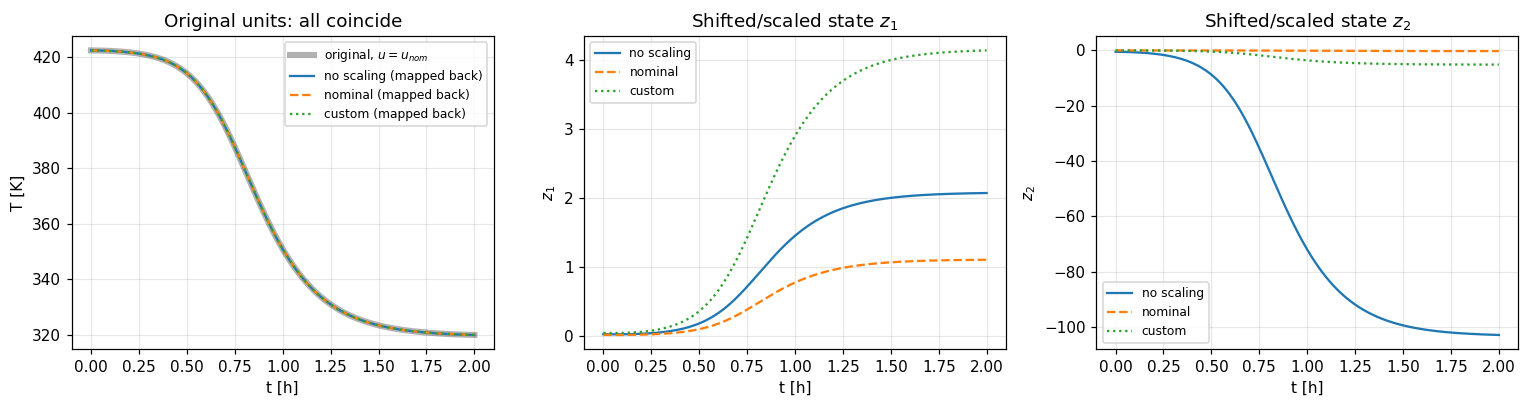

In [6]:
variants = {
    "no scaling": dict(scaling=None),
    "nominal"   : dict(scaling="nominal"),
    "custom"    : dict(scaling=([0.5, 20.0], [1.0, 1.0e4])),
}
f0_cstr_before = cstr.f0(ss["middle"])
systems = {}
for name, opts in variants.items():
    s = cstr.shift_to_steady_state(u_nom, x_guess=guesses["middle"], name=f"CSTR ({name})", **opts)
    systems[name] = s
    print(s)
    # the new maps against the defining formulas, at random points
    Dx, Du = np.diag(s.x_scale), np.diag(s.u_scale)
    err = 0.0
    for z_ in np.random.default_rng(0).normal(scale=0.05, size=(10, 2)):
        x_ = s.x_nom + s.x_scale * z_
        err = max(err,
                  np.max(np.abs(s.f0(z_) - np.linalg.solve(Dx, cstr.f0(x_) + cstr.G(x_) @ s.u_nom))),
                  np.max(np.abs(s.G(z_) - np.linalg.solve(Dx, cstr.G(x_) @ Du))))
    print(f"  new system is a different object: {s is not cstr}")
    print(f"  ||f~_0(0)||_inf = {np.max(np.abs(s.f0(np.zeros(2)))):.2e},  "
          f"max error of f~_0, G~ vs. formula = {err:.1e}\n")
print("original system unchanged:", np.array_equal(cstr.f0(ss["middle"]), f0_cstr_before))

# The same physical perturbation in every coordinate system
x_pert = ss["middle"] + np.array([0.02, -0.5])
t_eval = np.linspace(0.0, 2.0, 401)
ref = cstr.simulate(x_pert, (0.0, 2.0), u=u_nom, t_eval=t_eval)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(ref.t, ref.x[1], "k", lw=4, alpha=0.3, label="original, $u=u_{nom}$")
for (name, s), ls in zip(systems.items(), ["-", "--", ":"]):
    z0 = s.from_original_state(x_pert)
    r  = s.simulate_drift(z0, (0.0, 2.0), t_eval=t_eval)
    x_back = s.to_original_state(r.x)
    print(f"{name:10s}: z0 = {z0},  max |x_back - x_ref| = {np.max(np.abs(x_back - ref.x)):.2e}")
    ax[0].plot(r.t, x_back[1], ls, label=f"{name} (mapped back)")
    ax[1].plot(r.t, r.x[0], ls, label=name)
    ax[2].plot(r.t, r.x[1], ls, label=name)
ax[0].set(xlabel="t [h]", ylabel="T [K]", title="Original units: all coincide")
ax[1].set(xlabel="t [h]", ylabel="$z_1$", title="Shifted/scaled state $z_1$")
ax[2].set(xlabel="t [h]", ylabel="$z_2$", title="Shifted/scaled state $z_2$")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

The perturbation leaves the unstable middle steady state and goes to the high-temperature one. The time histories in original units agree for all three coordinate systems. Only the size of $z$ differs: with nominal scaling, $z$ is the relative deviation from the steady state.

`scaling='nominal'` handles a zero nominal component by leaving it unscaled and issuing a warning:

In [7]:
s_tmp = cstr.shift_to_steady_state([5.0, 0.0], x_guess=[3.5, 310.0], scaling="nominal")
print("u_scale =", s_tmp.u_scale)

[CSTR] warning: zero nominal input component(s) [1] left unscaled.
u_scale = [5. 1.]


### 1.6 Linearization at the origin — requirement (5)

$A = Df_0(0)$ and $B = G(0)$. The scalings must be consistent: $A_{scaled} = D_x^{-1} A\, D_x$ and $B_{scaled} = D_x^{-1} B\, D_u$, and the eigenvalues of $A$ do not depend on the coordinates. We also compare the linear model with the nonlinear system for a small perturbation.

--- no scaling ---
A =
[[-10.64596  -0.35663]
 [281.07591  12.75428]]
B =
[[ 2.12135e+00  0.00000e+00]
 [-1.22924e+02  4.32900e-03]]
eig(A) = [-5.       7.10832],  consistency errors: A 0.0e+00, B 0.0e+00

--- nominal ---
A =
[[-10.64596 -80.28509]
 [  1.24855  12.75428]]
B =
[[ 5.64596  0.     ]
 [-1.45327  0.20472]]
eig(A) = [-5.       7.10832],  consistency errors: A 1.6e-07, B 0.0e+00

--- custom ---
A =
[[-10.64596 -14.26518]
 [  7.0269   12.75428]]
B =
[[ 4.24271  0.     ]
 [-6.14622  2.1645 ]]
eig(A) = [-5.       7.10832],  consistency errors: A 5.4e-08, B 4.4e-16



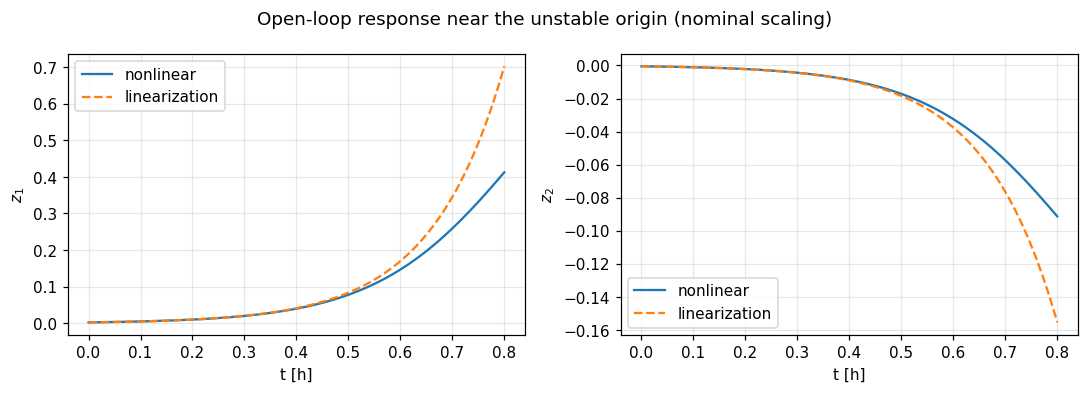

In [8]:
A0, B0 = systems["no scaling"].linearize()
for name, s in systems.items():
    A, B = s.linearize()
    Dx, Du = np.diag(s.x_scale), np.diag(s.u_scale)
    eA = np.max(np.abs(A - np.linalg.solve(Dx, A0 @ Dx)))
    eB = np.max(np.abs(B - np.linalg.solve(Dx, B0 @ Du)))
    print(f"--- {name} ---\nA =\n{A}\nB =\n{B}")
    print(f"eig(A) = {np.linalg.eigvals(A)},  consistency errors: A {eA:.1e}, B {eB:.1e}\n")

# Linear vs nonlinear response (nominal scaling), zero input, small perturbation
s = systems["nominal"]
A, B = s.linearize()
z0 = np.array([0.002, -0.0005])
t_eval = np.linspace(0.0, 0.8, 201)
r_nl = s.simulate_drift(z0, (0.0, 0.8), t_eval=t_eval)
from scipy.linalg import expm
z_lin = np.column_stack([expm(A * t) @ z0 for t in t_eval])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for i in range(2):
    ax[i].plot(t_eval, r_nl.x[i], label="nonlinear")
    ax[i].plot(t_eval, z_lin[i], "--", label="linearization")
    ax[i].set(xlabel="t [h]", ylabel=f"$z_{i+1}$")
    ax[i].legend()
fig.suptitle("Open-loop response near the unstable origin (nominal scaling)")
plt.tight_layout(); plt.show()

### 1.7 LQR design and closed-loop simulation — requirement (6)

`design_lqr(Q, R)` solves the continuous-time algebraic Riccati equation for $(A, B)$ and returns $K = R^{-1}B^\top P$. `simulate_closed_loop` then simulates the **nonlinear** system under the proportional controller $v = -Kz$.

We use the nominally scaled system with $Q = I$ and $R = I$. In these coordinates the weights penalize relative deviations.

In [9]:
s = systems["nominal"]
K = s.design_lqr(Q=np.eye(2), R=np.eye(2))
print(s)
print("\nP =\n", s.P)
print("open-loop   eig(A)    =", np.linalg.eigvals(s.linearize()[0]))
print("closed-loop eig(A-BK) =", np.linalg.eigvals(s.closed_loop_matrix()))
print("LQR input -K z at z = (0.1, 0.01):", -s.K @ np.array([0.1, 0.01]))

System CSTR (nominal): n = 2, m = 2
  x = x_offset + x_scale * z,  x_offset = [  1.87865 422.9245 ],  x_scale = [  1.87865 422.9245 ]
  u = u_offset + u_scale * v,  u_offset = [5.e+00 2.e+04],  u_scale = [5.e+00 2.e+04]
  LQR gain K = [[ -0.4565 -13.2947]
 [  0.1705   2.535 ]]

P =
 [[ 0.13346  0.83262]
 [ 0.83262 12.3829 ]]
open-loop   eig(A)    = [-5.       7.10832]
closed-loop eig(A-BK) = [-7.57708+1.62254j -7.57708-1.62254j]
LQR input -K z at z = (0.1, 0.01): [ 0.1786 -0.0424]


[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2]: total computational time = 0.0536 s
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2]: total computational time = 0.0484 s
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2]: total computational time = 0.0469 s
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2]: total computational time = 0.0616 s
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2]: total computational time = 0.0547 s


SimulationResult(mode='closed loop (v = -K z)', t=[0, 2], steps=401, success=True, wall_time=0.0536s)


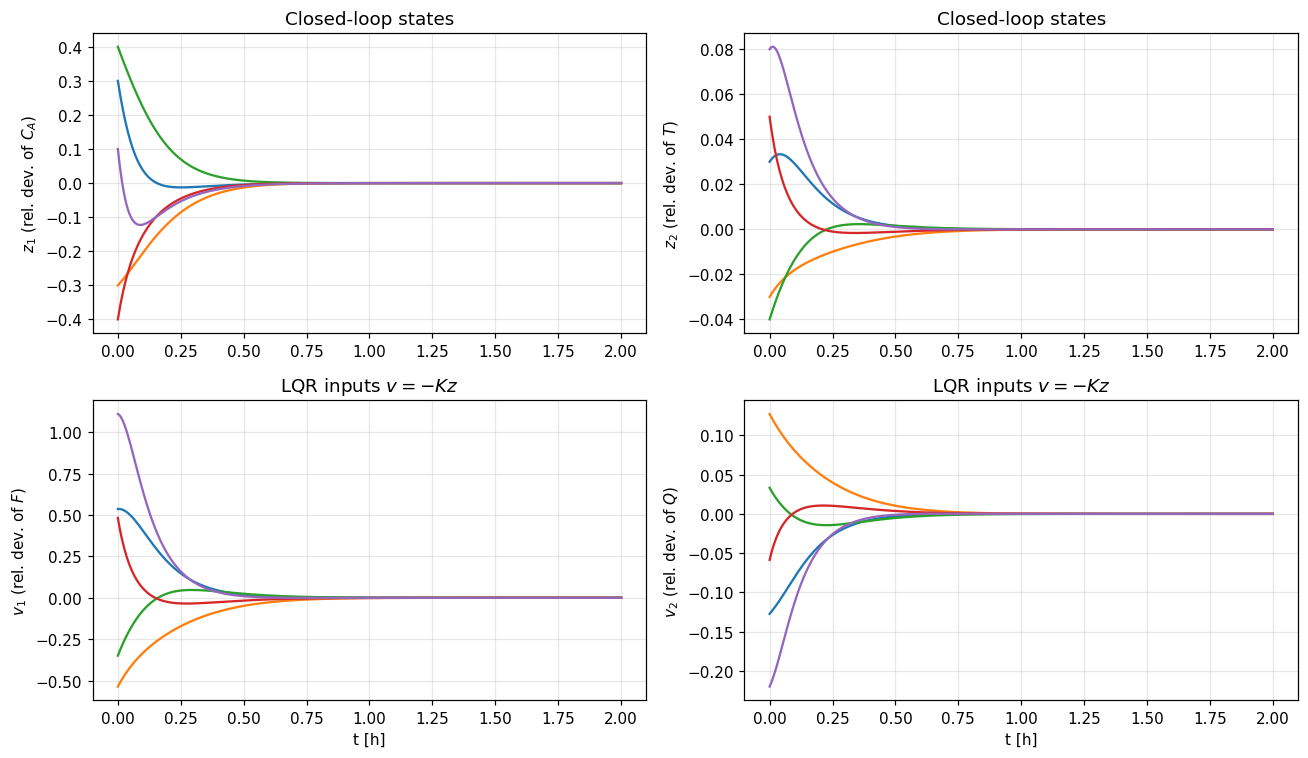

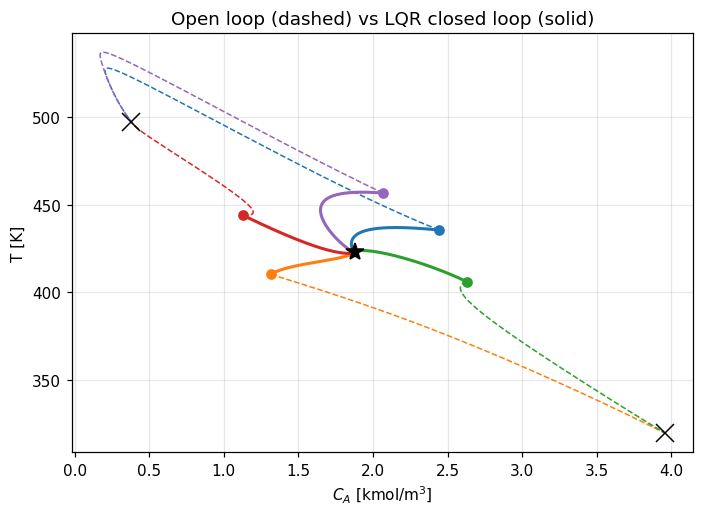

final |z| (closed loop): ['2.3e-08', '2.4e-07', '1.1e-07', '9.2e-08', '7.7e-08']


In [10]:
z0_list = [[0.3, 0.03], [-0.3, -0.03], [0.4, -0.04], [-0.4, 0.05], [0.1, 0.08]]
t_eval = np.linspace(0.0, 2.0, 401)
cl_runs = [s.simulate_closed_loop(z0, (0.0, 2.0), t_eval=t_eval) for z0 in z0_list]
ol_runs = [s.simulate_drift(z0, (0.0, 2.0), t_eval=t_eval) for z0 in z0_list]
print(cl_runs[0])

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for z0, rc in zip(z0_list, cl_runs):
    ax[0, 0].plot(rc.t, rc.x[0]); ax[0, 1].plot(rc.t, rc.x[1])
    ax[1, 0].plot(rc.t, rc.u[0]); ax[1, 1].plot(rc.t, rc.u[1])
ax[0, 0].set(ylabel="$z_1$ (rel. dev. of $C_A$)", title="Closed-loop states")
ax[0, 1].set(ylabel="$z_2$ (rel. dev. of $T$)",   title="Closed-loop states")
ax[1, 0].set(xlabel="t [h]", ylabel="$v_1$ (rel. dev. of $F$)", title="LQR inputs $v=-Kz$")
ax[1, 1].set(xlabel="t [h]", ylabel="$v_2$ (rel. dev. of $Q$)", title="LQR inputs $v=-Kz$")
plt.tight_layout(); plt.show()

# Phase plane in original units: open loop (dashed) vs closed loop (solid)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for k, (rc, ro) in enumerate(zip(cl_runs, ol_runs)):
    c = f"C{k}"
    xc, xo = s.to_original_state(rc.x), s.to_original_state(ro.x)
    ax.plot(xo[0], xo[1], "--", color=c, lw=1)
    ax.plot(xc[0], xc[1], "-",  color=c, lw=2)
    ax.plot(*xc[:, 0], "o", color=c)
for key, xs in ss.items():
    ax.plot(*xs, "k*" if key == "middle" else "kx", ms=12)
ax.set(xlabel="$C_A$ [kmol/m$^3$]", ylabel="T [K]",
       title="Open loop (dashed) vs LQR closed loop (solid)")
plt.tight_layout(); plt.show()

print("final |z| (closed loop):", [f"{np.linalg.norm(r.x[:, -1]):.1e}" for r in cl_runs])

Without control, the trajectories leave the unstable middle steady state (★) for the low- or high-temperature steady states (×). The LQR controller, designed on the linearization, brings all five initial conditions back to the operating point.

Finally, the realized cost $\int_0^\infty (z^\top Q z + v^\top R v)\,dt$ of the nonlinear closed loop should be close to the LQR prediction $z_0^\top P z_0$ for small $z_0$ and drift apart as $z_0$ grows. The Koopman method aims to close this gap.

In [11]:
from scipy.integrate import trapezoid
t_eval = np.linspace(0.0, 4.0, 4001)
d = np.array([1.0, 0.1])
for a in [0.01, 0.1, 0.3, 0.5]:
    z0 = a * d
    r = s.simulate_closed_loop(z0, (0.0, 4.0), t_eval=t_eval, rtol=1e-9, atol=1e-11)
    stage = np.einsum("it,ij,jt->t", r.x, s.Q, r.x) + np.einsum("it,ij,jt->t", r.u, s.R, r.u)
    J = trapezoid(stage, r.t)
    print(f"z0 = {z0}:  realized J = {J:.5e},  z0'Pz0 = {z0 @ s.P @ z0:.5e},  ratio = {J / (z0 @ s.P @ z0):.4f}")

[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 4]: total computational time = 0.2706 s
z0 = [0.01  0.001]:  realized J = 4.23524e-05,  z0'Pz0 = 4.23816e-05,  ratio = 0.9993


[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 4]: total computational time = 0.2637 s
z0 = [0.1  0.01]:  realized J = 4.24514e-03,  z0'Pz0 = 4.23816e-03,  ratio = 1.0016


[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 4]: total computational time = 0.4461 s
z0 = [0.3  0.03]:  realized J = 4.07791e-02,  z0'Pz0 = 3.81435e-02,  ratio = 1.0691


[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 4]: total computational time = 0.4306 s
z0 = [0.5  0.05]:  realized J = 1.32355e-01,  z0'Pz0 = 1.05954e-01,  ratio = 1.2492


---
## Part 2. `mpc.py`: nominal nonlinear MPC

`ModelPredictiveControl(model, horizon=N, dt=Δt, ...)` solves the following problem at every sampling instant, with zero-order-hold inputs:

$$
\min_{u_0,\dots,u_{N-1}} \; \sum_{k=0}^{N-1} \Delta t\,\big(x_k^\top Q x_k + u_k^\top R u_k\big) + x_N^\top P x_N
\quad \text{s.t.}\quad x_0 = x(t),\;\; x_{k+1} = \Phi_{\Delta t}(x_k, u_k),\;\; u_{\min}\le u_k\le u_{\max},\;\; x_{\min}\le x_k\le x_{\max}.
$$

- $\Phi_{\Delta t}$ is the model's flow over one sampling interval, computed with RK4 substeps.
- By default the terminal weight $P$ solves the continuous-time Riccati equation of the linearization, the same $P$ as the LQR.

The problem is solved by multiple shooting with CasADi and IPOPT. The symbolic model comes from `InputAffineSystem.casadi_rhs()`, which traces the NumPy functions $f_0$ and $f_j$. Derivatives are exact (automatic differentiation), and each solve is warm-started from the previous solution shifted by one step.

We use the nominally scaled CSTR `s` from Part 1. The prediction horizon is $N\Delta t = 20 \times 0.025 = 0.5$ h.

In [12]:
from mpc import ModelPredictiveControl
from scipy.integrate import trapezoid

s = systems["nominal"]
mpc = ModelPredictiveControl(s, horizon=20, dt=0.025, Q=np.eye(2), R=np.eye(2))
print(mpc)
print("terminal weight P equals the LQR Riccati solution:", np.allclose(mpc.P, s.P))

# The traced CasADi model must agree with the NumPy model
F_ca = s.casadi_rhs()
rng = np.random.default_rng(1)
err = max(np.max(np.abs(np.asarray(F_ca(z_, v_)).ravel() - s.rhs(z_, v_)))
          for z_, v_ in zip(rng.normal(scale=0.2, size=(20, 2)), rng.normal(scale=0.2, size=(20, 2))))
print(f"max |CasADi rhs - NumPy rhs| over 20 random points = {err:.2e}")

ModelPredictiveControl(model='CSTR (nominal)', N=20, dt=0.025)
terminal weight P equals the LQR Riccati solution: True
max |CasADi rhs - NumPy rhs| over 20 random points = 3.55e-15


### 2.1 One optimal control problem: checking the prediction

We solve the problem from $z_0 = (0.4, -0.04)$ and apply the optimal piecewise-constant inputs to the plant, simulated with an adaptive ODE solver. The plant trajectory should match the RK4 prediction at the sampling instants.

OCPSolution(cost=0.0201143, success=True, nit=9, solve_time=0.010s) | Solve_Succeeded
first MPC input  : [-0.34498  0.04118]
LQR input -K z0  : [-0.3492   0.03322]


[CSTR (nominal)] feedback / time-varying input simulation on t = [0, 0.5]: total computational time = 0.4014 s
max |prediction - plant| at the sampling instants = 2.36e-07


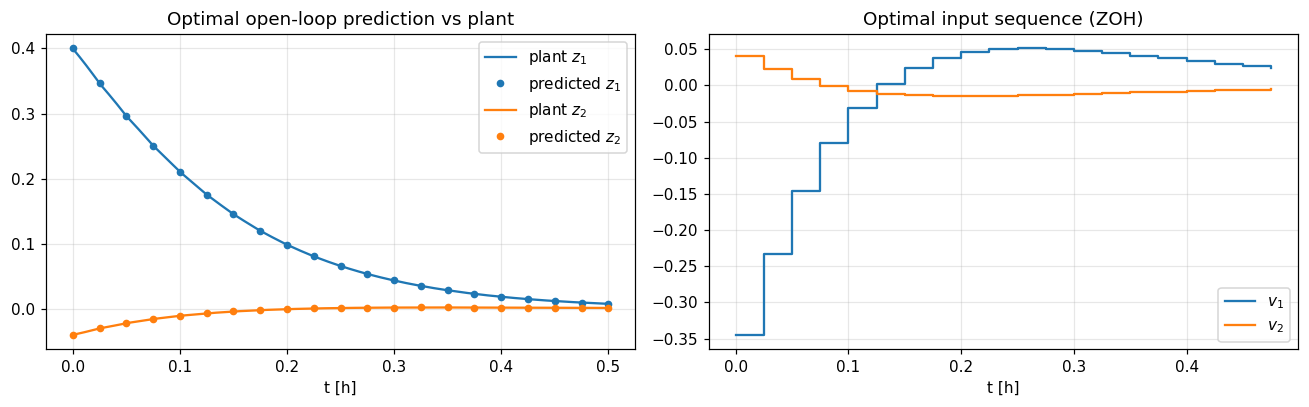

In [13]:
z0 = np.array([0.4, -0.04])

mpc.reset()
sol = mpc.solve(z0)
print(sol, "|", sol.message)
print("first MPC input  :", sol.u[:, 0])
print("LQR input -K z0  :", -s.K @ z0)

# apply the optimal open-loop inputs to the plant (adaptive solver)
u_ol = lambda t, z: sol.u[:, min(int(t / mpc.dt), mpc.N - 1)]
r_ol = s.simulate(z0, (0.0, mpc.N * mpc.dt), u=u_ol,
                  t_eval=np.linspace(0, mpc.N * mpc.dt, 401), max_step=mpc.dt / 10)
x_at_samples = np.column_stack([np.interp(sol.t, r_ol.t, r_ol.x[i]) for i in range(2)]).T
print(f"max |prediction - plant| at the sampling instants = {np.max(np.abs(sol.x - x_at_samples)):.2e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for i in range(2):
    ax[0].plot(r_ol.t, r_ol.x[i], f"C{i}", label=f"plant $z_{i+1}$")
    ax[0].plot(sol.t, sol.x[i], f"C{i}o", ms=4, label=f"predicted $z_{i+1}$")
    ax[1].step(sol.t[:-1], sol.u[i], where="post", label=f"$v_{i+1}$")
ax[0].set(xlabel="t [h]", title="Optimal open-loop prediction vs plant"); ax[0].legend()
ax[1].set(xlabel="t [h]", title="Optimal input sequence (ZOH)"); ax[1].legend()
plt.tight_layout(); plt.show()

### 2.2 Closed loop: unconstrained MPC vs LQR

`simulate_closed_loop(z0, n_steps)` measures the plant state at each $t_k = k\Delta t$, solves the problem, warm-started from the previous solution shifted by one step, and applies the first input over $[t_k, t_{k+1})$. Without constraints and near the origin, the MPC should behave almost like the LQR.

[MPC: CSTR (nominal)] closed loop, 40 steps: total computational time = 0.2257 s (OCP solves 0.1142 s, mean 0.0029 s, max 0.0122 s per step)
MPCSimulationResult(steps=40, all_success=True, mean_solve_time=0.003s, wall_time=0.226s)
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.0327 s


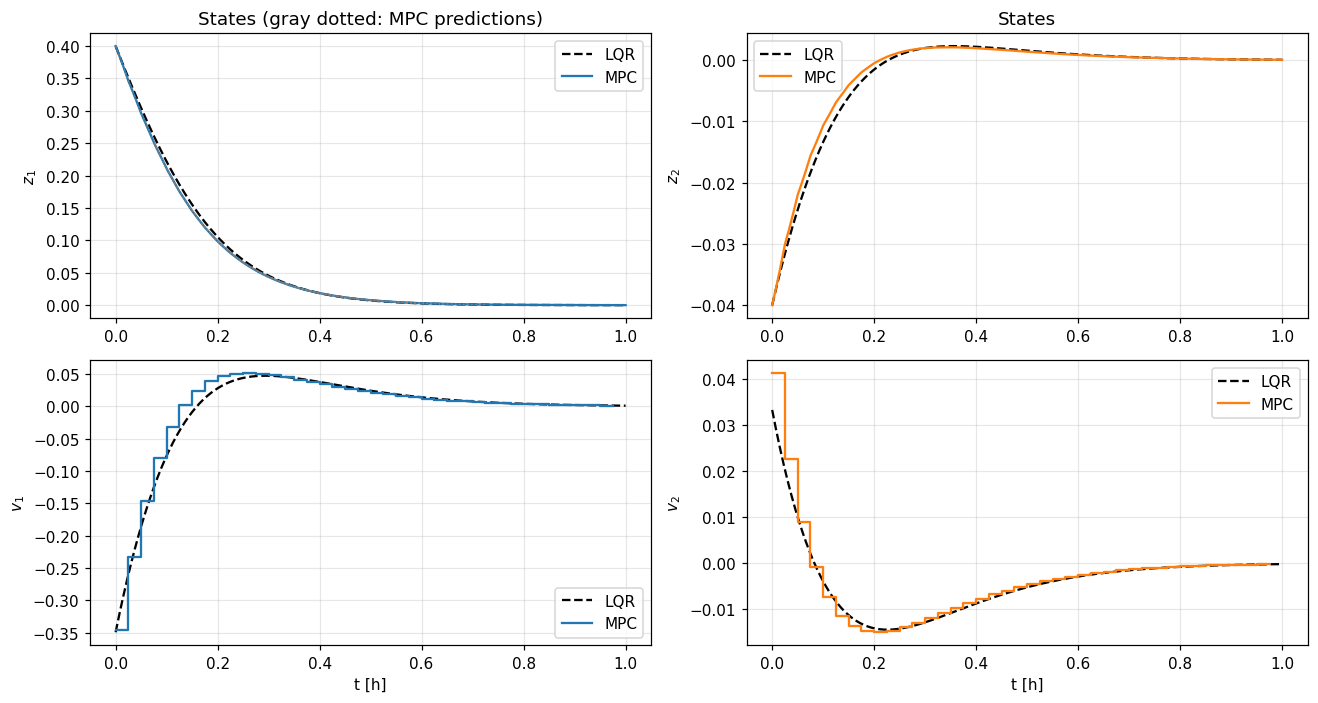

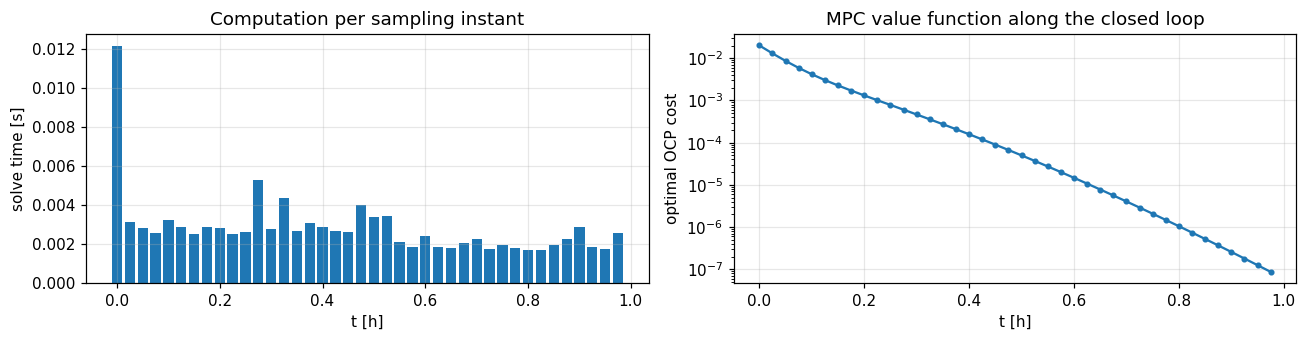

In [14]:
res = mpc.simulate_closed_loop(z0, n_steps=40, store_predictions=True)
print(res)
lqr = s.simulate_closed_loop(z0, (0.0, 1.0), t_eval=np.linspace(0, 1, 401))

fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
for i in range(2):
    ax[0, i].plot(lqr.t, lqr.x[i], "k--", label="LQR")
    ax[0, i].plot(res.t, res.x[i], f"C{i}", label="MPC")
    ax[0, i].set(ylabel=f"$z_{i+1}$"); ax[0, i].legend()
    ax[1, i].plot(lqr.t, lqr.u[i], "k--", label="LQR")
    ax[1, i].step(res.t_samples[:-1], res.u_samples[i], f"C{i}", where="post", label="MPC")
    ax[1, i].set(xlabel="t [h]", ylabel=f"$v_{i+1}$"); ax[1, i].legend()
# a few predicted trajectories
for p, tk in zip(res.predictions[:12:3], res.t_samples[:12:3]):
    ax[0, 0].plot(tk + p.t, p.x[0], ":", color="gray", lw=1)
ax[0, 0].set_title("States (gray dotted: MPC predictions)"); ax[0, 1].set_title("States")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].bar(res.t_samples[:-1], res.solve_times, width=mpc.dt * 0.8)
ax[0].set(xlabel="t [h]", ylabel="solve time [s]", title="Computation per sampling instant")
ax[1].semilogy(res.t_samples[:-1], res.costs, "o-", ms=3)
ax[1].set(xlabel="t [h]", ylabel="optimal OCP cost", title="MPC value function along the closed loop")
plt.tight_layout(); plt.show()

### 2.3 Realized closed-loop cost: MPC vs LQR

In Part 1, the LQR's realized cost $\int_0^\infty (z^\top Q z + v^\top R v)\,dt$ grew to about 25% above $z_0^\top P z_0$ as $z_0$ grew. The MPC accounts for the nonlinearity over its horizon, so its realized cost should be lower for larger $z_0$.

Note that the MPC applies sample-and-hold inputs, while the LQR acts in continuous time, so the comparison slightly favors the LQR.

In [15]:
def realized_cost(t, z, v_fine=None, t_s=None, v_s=None, Q=s.Q, R=s.R):
    state_part = trapezoid(np.einsum("it,ij,jt->t", z, Q, z), t)
    if v_s is not None:                       # piecewise-constant input: exact integral
        input_part = np.sum(np.diff(t_s) * np.einsum("it,ij,jt->t", v_s, R, v_s))
    else:
        input_part = trapezoid(np.einsum("it,ij,jt->t", v_fine, R, v_fine), t)
    return state_part + input_part

d = np.array([1.0, 0.1])
T_end, rows = 2.5, []
for a in [0.1, 0.3, 0.5]:
    zz = a * d
    r_m = mpc.simulate_closed_loop(zz, n_steps=int(round(T_end / mpc.dt)), n_fine=20)
    r_l = s.simulate_closed_loop(zz, (0.0, T_end), t_eval=np.linspace(0, T_end, 5001), rtol=1e-9, atol=1e-11)
    J_m = realized_cost(r_m.t, r_m.x, t_s=r_m.t_samples, v_s=r_m.u_samples)
    J_l = realized_cost(r_l.t, r_l.x, v_fine=r_l.u)
    rows.append((a, zz @ s.P @ zz, J_l, J_m, r_m.costs[0]))
    print(f"z0 = {zz}:  z0'Pz0 = {rows[-1][1]:.4e} | LQR J = {J_l:.4e} | MPC J = {J_m:.4e} "
          f"| MPC/LQR = {J_m / J_l:.4f} | MPC value V_N(z0) = {r_m.costs[0]:.4e}")

[MPC: CSTR (nominal)] closed loop, 100 steps: total computational time = 0.3802 s (OCP solves 0.1854 s, mean 0.0019 s, max 0.0079 s per step)
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2.5]: total computational time = 0.2062 s


z0 = [0.1  0.01]:  z0'Pz0 = 4.2382e-03 | LQR J = 4.2451e-03 | MPC J = 4.2095e-03 | MPC/LQR = 0.9916 | MPC value V_N(z0) = 4.3498e-03


[MPC: CSTR (nominal)] closed loop, 100 steps: total computational time = 0.4116 s (OCP solves 0.2032 s, mean 0.0020 s, max 0.0108 s per step)


[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2.5]: total computational time = 0.3352 s
z0 = [0.3  0.03]:  z0'Pz0 = 3.8143e-02 | LQR J = 4.0779e-02 | MPC J = 3.7411e-02 | MPC/LQR = 0.9174 | MPC value V_N(z0) = 3.8714e-02


[MPC: CSTR (nominal)] closed loop, 100 steps: total computational time = 0.4442 s (OCP solves 0.2177 s, mean 0.0022 s, max 0.0123 s per step)


[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 2.5]: total computational time = 0.4278 s
z0 = [0.5  0.05]:  z0'Pz0 = 1.0595e-01 | LQR J = 1.3235e-01 | MPC J = 1.0381e-01 | MPC/LQR = 0.7843 | MPC value V_N(z0) = 1.0756e-01


### 2.4 Input constraints

With $|v_j| \le 0.3$, so that $F$ and $Q$ stay within ±30% of nominal, the unconstrained LQR from $z_0 = (0.4, -0.04)$ would ask for $v_1 \approx -0.35$. We compare the constrained MPC with the LQR whose input is clipped to the same bounds.

ModelPredictiveControl(model='CSTR (nominal)', N=20, dt=0.025)


[MPC: CSTR (nominal)] closed loop, 40 steps: total computational time = 0.2350 s (OCP solves 0.1237 s, mean 0.0031 s, max 0.0123 s per step)
MPCSimulationResult(steps=40, all_success=True, mean_solve_time=0.003s, wall_time=0.235s)
[CSTR (nominal)] feedback / time-varying input simulation on t = [0, 1]: total computational time = 0.0470 s
MPC input range: [-0.3     -0.01463] [0.04994 0.04523]


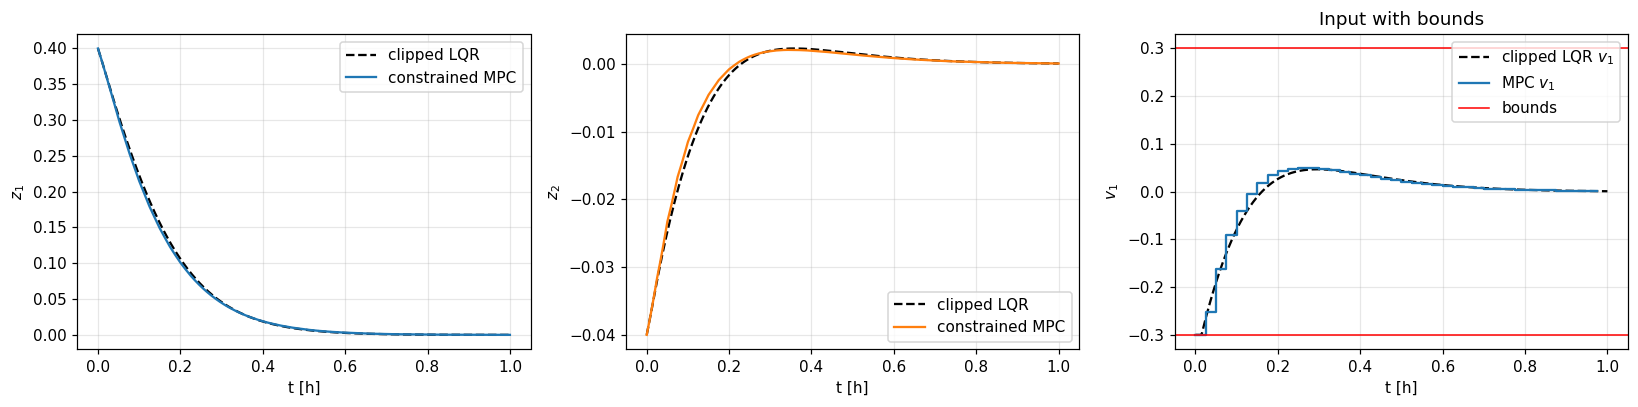

In [16]:
v_bound = 0.3
mpc_u = ModelPredictiveControl(s, horizon=20, dt=0.025, u_min=-v_bound, u_max=v_bound)
print(mpc_u)
res_u = mpc_u.simulate_closed_loop(z0, n_steps=40)
print(res_u)
sat_lqr = s.simulate(z0, (0.0, 1.0), u=lambda t, z: np.clip(-s.K @ z, -v_bound, v_bound),
                     t_eval=np.linspace(0, 1, 401))
print("MPC input range:", res_u.u_samples.min(axis=1), res_u.u_samples.max(axis=1))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for i in range(2):
    ax[i].plot(sat_lqr.t, sat_lqr.x[i], "k--", label="clipped LQR")
    ax[i].plot(res_u.t, res_u.x[i], f"C{i}", label="constrained MPC")
    ax[i].set(xlabel="t [h]", ylabel=f"$z_{i+1}$"); ax[i].legend()
ax[2].plot(sat_lqr.t, sat_lqr.u[0], "k--", label="clipped LQR $v_1$")
ax[2].step(res_u.t_samples[:-1], res_u.u_samples[0], "C0", where="post", label="MPC $v_1$")
ax[2].axhline(-v_bound, color="r", lw=1); ax[2].axhline(v_bound, color="r", lw=1, label="bounds")
ax[2].set(xlabel="t [h]", ylabel="$v_1$", title="Input with bounds"); ax[2].legend()
plt.tight_layout(); plt.show()

### 2.5 State constraints

Starting from $z_0 = (0.3, 0.03)$, the LQR closed loop overshoots in temperature. We add the constraint $z_2 \le 0.03$, i.e. $T \le 1.03\,T_{nom} \approx 435.6$ K. The MPC imposes it on the predicted states at the sampling instants $k = 1, \dots, N$.

ModelPredictiveControl(model='CSTR (nominal)', N=20, dt=0.025)


[MPC: CSTR (nominal)] closed loop, 40 steps: total computational time = 0.2255 s (OCP solves 0.1176 s, mean 0.0029 s, max 0.0119 s per step)
MPCSimulationResult(steps=40, all_success=True, mean_solve_time=0.003s, wall_time=0.226s)
[CSTR (nominal)] closed loop (v = -K z) simulation on t = [0, 1]: total computational time = 0.0404 s
max z2: LQR = 0.03336,  MPC (samples) = 0.03000, MPC (continuous) = 0.03000


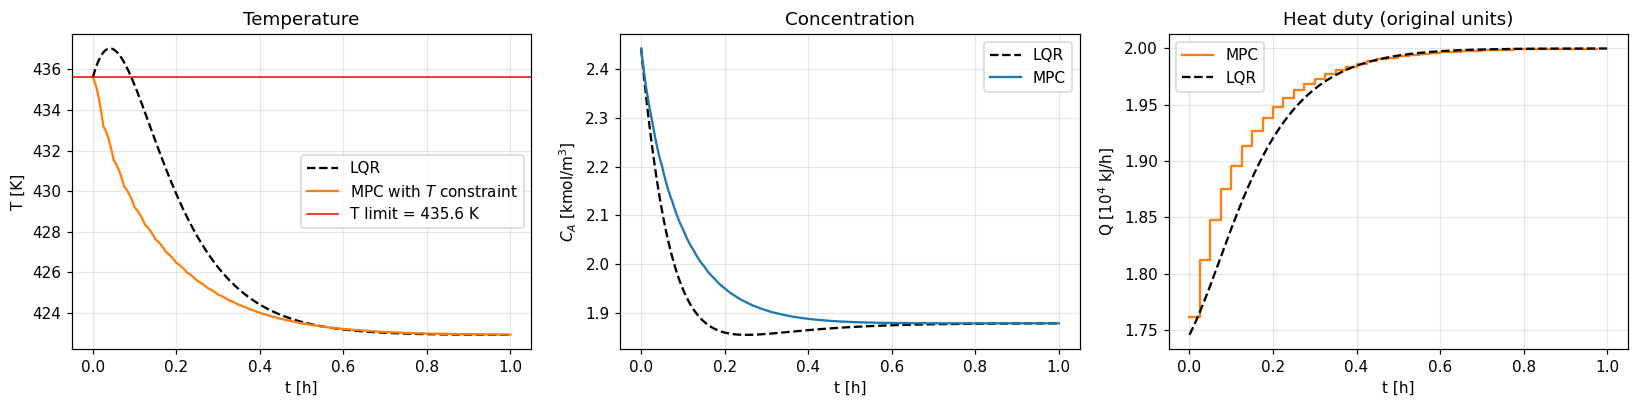

In [17]:
z0_c = np.array([0.3, 0.03])
z2_max = 0.03
mpc_x = ModelPredictiveControl(s, horizon=20, dt=0.025, x_max=[np.inf, z2_max])
print(mpc_x)
res_x = mpc_x.simulate_closed_loop(z0_c, n_steps=40)
print(res_x)
lqr_c = s.simulate_closed_loop(z0_c, (0.0, 1.0), t_eval=np.linspace(0, 1, 401))
print(f"max z2: LQR = {lqr_c.x[1].max():.5f},  MPC (samples) = {res_x.x_samples[1].max():.5f}, "
      f"MPC (continuous) = {res_x.x[1].max():.5f}")

T_lim = s.to_original_state(np.array([0.0, z2_max]))[1]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(lqr_c.t, s.to_original_state(lqr_c.x)[1], "k--", label="LQR")
ax[0].plot(res_x.t, s.to_original_state(res_x.x)[1], "C1", label="MPC with $T$ constraint")
ax[0].axhline(T_lim, color="r", lw=1, label=f"T limit = {T_lim:.1f} K")
ax[0].set(xlabel="t [h]", ylabel="T [K]", title="Temperature"); ax[0].legend()
ax[1].plot(lqr_c.t, s.to_original_state(lqr_c.x)[0], "k--", label="LQR")
ax[1].plot(res_x.t, s.to_original_state(res_x.x)[0], "C0", label="MPC")
ax[1].set(xlabel="t [h]", ylabel="$C_A$ [kmol/m$^3$]", title="Concentration"); ax[1].legend()
u_orig = s.to_original_input(res_x.u_samples)
ax[2].step(res_x.t_samples[:-1], u_orig[1] / 1e4, "C1", where="post", label="MPC")
ax[2].plot(lqr_c.t, s.to_original_input(lqr_c.u)[1] / 1e4, "k--", label="LQR")
ax[2].set(xlabel="t [h]", ylabel="Q [$10^4$ kJ/h]", title="Heat duty (original units)"); ax[2].legend()
plt.tight_layout(); plt.show()

### 2.6 Plant-model mismatch (optional `plant` argument)

The MPC is *nominal*: it predicts with `model`. Passing `plant=` simulates a different system in closed loop. Here the plant's pre-exponential factor $k_0$ is 10% higher, and `transform` expresses the plant in the model's dimensionless coordinates.

The controller still stabilizes the plant, but with a steady-state offset, because nominal MPC has no integral action or disturbance model.

System CSTR plant (k0 +10%), scaled: n = 2, m = 2
  x = x_offset + x_scale * z,  x_offset = [  1.87865 422.9245 ],  x_scale = [  1.87865 422.9245 ]
  u = u_offset + u_scale * v,  u_offset = [5.e+00 2.e+04],  u_scale = [5.e+00 2.e+04]


[MPC: CSTR plant (k0 +10%), scaled] closed loop, 60 steps: total computational time = 0.3795 s (OCP solves 0.2392 s, mean 0.0040 s, max 0.0141 s per step)


[MPC: CSTR (nominal)] closed loop, 60 steps: total computational time = 0.2992 s (OCP solves 0.1517 s, mean 0.0025 s, max 0.0096 s per step)
MPCSimulationResult(steps=60, all_success=True, mean_solve_time=0.004s, wall_time=0.379s)
final state, nominal plant : [-3.63619e-06  1.44867e-06]
final state, perturbed plant: [-0.09798  0.01592]


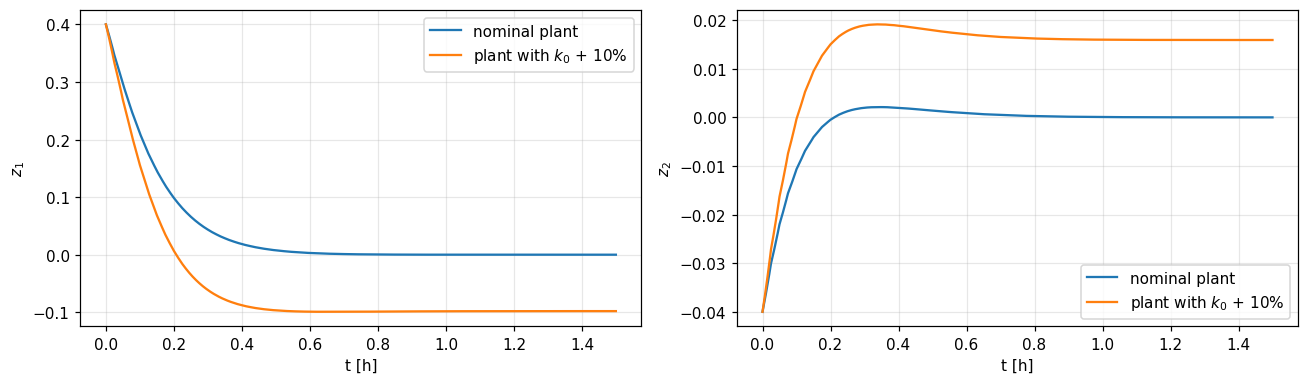

In [18]:
def f0_plant(x, k0p=1.1 * k0):
    CA, T = x
    r = k0p * np.exp(-E / (Rg * T)) * CA
    return np.array([-r, -dH / (rho * cp) * r])

plant_orig = InputAffineSystem(f0_plant, [f1, f2], 2, 2, name="CSTR plant (k0 +10%)", x_test=[2.0, 400.0])
plant = plant_orig.transform(s.x_offset, s.x_scale, s.u_offset, s.u_scale, name="CSTR plant (k0 +10%), scaled")
print(plant)
res_p = mpc.simulate_closed_loop(z0, n_steps=60, plant=plant)
res_n = mpc.simulate_closed_loop(z0, n_steps=60)
print(res_p)
print("final state, nominal plant :", res_n.x_samples[:, -1])
print("final state, perturbed plant:", res_p.x_samples[:, -1])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i in range(2):
    ax[i].plot(res_n.t, res_n.x[i], label="nominal plant")
    ax[i].plot(res_p.t, res_p.x[i], label="plant with $k_0$ + 10%")
    ax[i].set(xlabel="t [h]", ylabel=f"$z_{i+1}$"); ax[i].legend()
plt.tight_layout(); plt.show()

---
## Part 3. `dynamics.py`: data collection from the vector fields of a scaled system

### 3.1 Sampling and simulating every vector field

`collect_data(n_samples, half_side_lengths, tau, ...)` draws initial conditions $z^{(i)}$ in the hypercube $\prod_k [-L_k, L_k]$ around the origin, i.e. the steady state of the scaled system. The half side lengths can be one scalar for every dimension or one value per dimension.

From each $z^{(i)}$ it simulates **every** vector field over $[0, \tau]$ on a common time grid:

$$
\dot z = \tilde f_0(z) \quad(\text{drift, } v = 0), \qquad \dot z = \tilde f_j(z) \quad (\text{unit input on channel } j,\ \text{no drift}),\ j = 1,\dots,m .
$$

The result is a `VectorFieldData` object:

| attribute | shape | meaning |
|---|---|---|
| `X0` | $(n, N_s)$ | sampled initial conditions |
| `t` | $(N_t,)$ | common time grid |
| `X` | $(m+1, n, N_t, N_s)$ | `X[j, :, l, i]` is the flow of $\tilde f_j$ from sample $i$ at time $t_l$ |
| `F0` | $(m+1, n, N_s)$ | `F0[j, :, i]` $= \tilde f_j(z^{(i)})$ |


In [19]:
s = systems["nominal"]          # dimensionless CSTR, origin = unstable steady state
L = np.array([0.2, 0.02])       # C_A within ±20 %, T within ±2 % (≈ ±8.5 K) of nominal
data = s.collect_data(n_samples=200, half_side_lengths=L, tau=0.2, n_time=101, rng=0)
print(data)
print("X0:", data.X0.shape, "| t:", data.t.shape, "| X:", data.X.shape,
      "| F0:", data.F0.shape)

# Same half side length in every dimension
data_eq = s.collect_data(n_samples=128, half_side_lengths=0.05, tau=0.2, rng=0)
print(data_eq)

[CSTR (nominal)] data collection: 200 samples x 3 vector fields: total computational time = 3.6646 s
VectorFieldData(n_samples=200, n_fields=3, half_side_lengths=[0.2  0.02], tau=0.2, N_t=101, wall_time=3.665s)
X0: (2, 200) | t: (101,) | X: (3, 2, 101, 200) | F0: (3, 2, 200)


[CSTR (nominal)] data collection: 128 samples x 3 vector fields: total computational time = 2.8485 s
VectorFieldData(n_samples=128, n_fields=3, half_side_lengths=[0.05 0.05], tau=0.2, N_t=101, wall_time=2.848s)


### 3.2 Checks

1. All samples lie in the hypercube, and every trajectory starts at its sample.
2. Each stored trajectory equals a direct call to `simulate_field(j, z0, ...)`.
3. The stored vector-field values match the slope of the trajectories at $t = 0$: `F0[j]` $\approx (X(t_1) - X(t_0))/t_1$, a forward difference of order $O(t_1)$.
4. $\tilde f_2$ is a constant field, so its flow is exactly linear in time.

In [20]:
for d in (data, data_eq):
    inside = np.all(np.abs(d.X0) <= d.half_side_lengths[:, None])
    starts = np.max(np.abs(d.X[:, :, 0, :] - d.X0[None]))
    print(f"L = {d.half_side_lengths}: all samples inside hypercube: {inside};  max |X(t=0) - X0| = {starts:.1e}")

i = 7
for j in range(data.n_fields):
    r = s.simulate_field(j, data.X0[:, i], (0.0, data.tau), t_eval=data.t)
    print(f"f_{j}: max |stored - direct simulate_field| = {np.max(np.abs(data.trajectory(j, i) - r.x)):.1e}")

dt1 = data.t[1] - data.t[0]
for j in range(data.n_fields):
    slope = (data.X[j, :, 1, :] - data.X[j, :, 0, :]) / dt1
    rel = np.max(np.abs(slope - data.F0[j])) / np.max(np.abs(data.F0[j]))
    print(f"f_{j}: max rel. |forward difference - F0| = {rel:.1e}   (dt = {dt1:.3g})")

lin = data.X0[:, None, :] + data.t[None, :, None] * data.F0[2][:, None, :]   # z0 + t f_2, (n, N_t, N_s)
print(f"f_2 flow vs exact z0 + t f_2: max error = {np.max(np.abs(data.field(2) - lin)):.1e}")

L = [0.2  0.02]: all samples inside hypercube: True;  max |X(t=0) - X0| = 0.0e+00
L = [0.05 0.05]: all samples inside hypercube: True;  max |X(t=0) - X0| = 0.0e+00
f_0: max |stored - direct simulate_field| = 0.0e+00


f_1: max |stored - direct simulate_field| = 0.0e+00
f_2: max |stored - direct simulate_field| = 0.0e+00
f_0: max rel. |forward difference - F0| = 5.4e-03   (dt = 0.002)
f_1: max rel. |forward difference - F0| = 5.0e-03   (dt = 0.002)
f_2: max rel. |forward difference - F0| = 3.7e-15   (dt = 0.002)
f_2 flow vs exact z0 + t f_2: max error = 4.9e-17


### 3.3 Visualization

The plots show the samples in their hypercubes, and trajectories of all three vector fields from the first 40 samples.

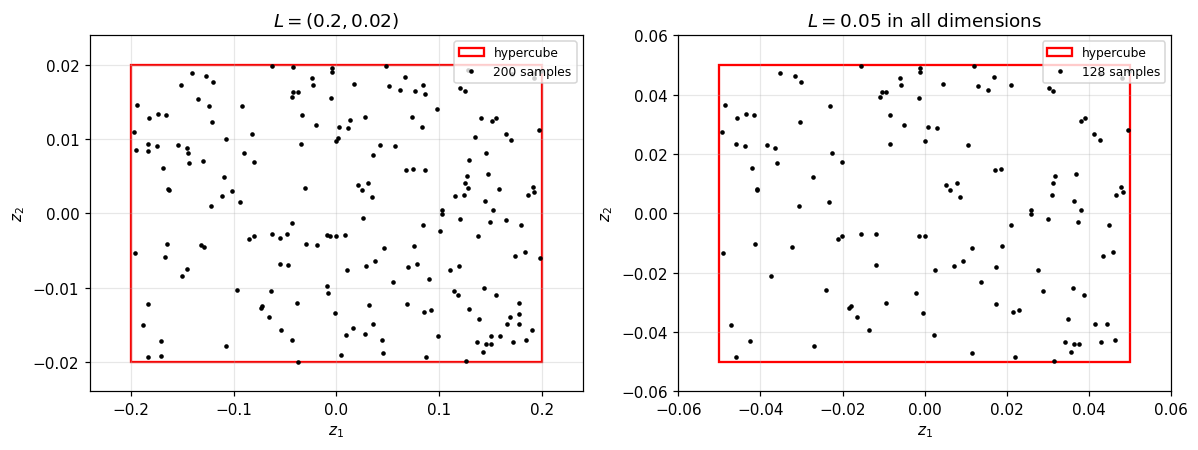

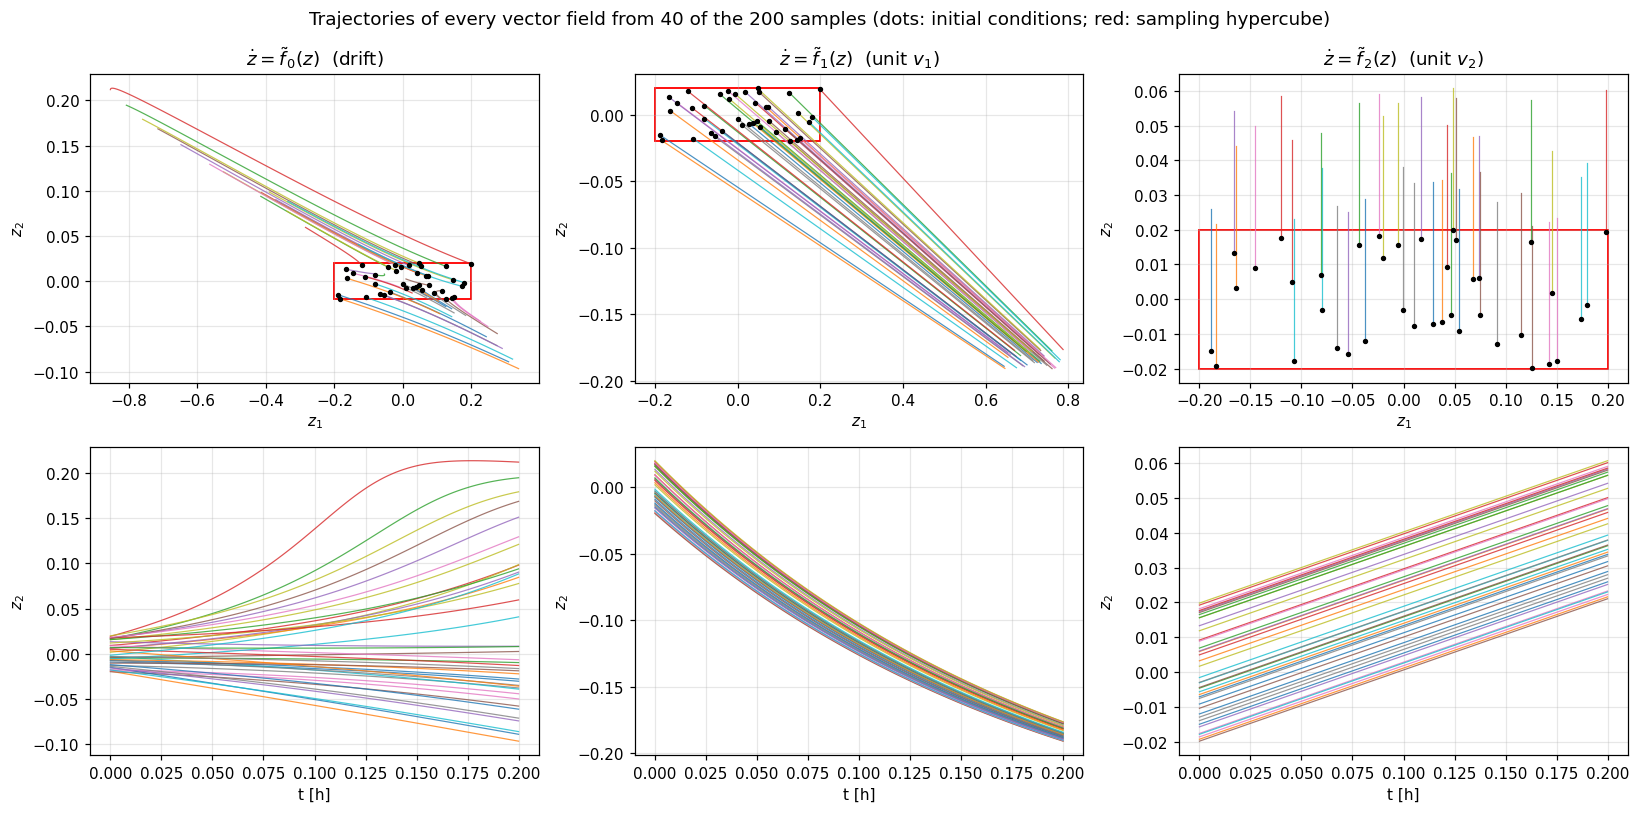

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, d, title in ((ax[0], data, "$L = (0.2, 0.02)$"),
                    (ax[1], data_eq, "$L = 0.05$ in all dimensions")):
    c, Lh = np.zeros(2), d.half_side_lengths
    a.add_patch(plt.Rectangle(c - Lh, 2 * Lh[0], 2 * Lh[1], fill=False, ec="r", lw=1.5, label="hypercube"))
    a.plot(d.X0[0], d.X0[1], "k.", ms=4, label=f"{d.n_samples} samples")
    a.set(xlabel="$z_1$", ylabel="$z_2$", title=title)
    a.margins(0.1); a.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

names = ["$\\dot z = \\tilde f_0(z)$  (drift)", "$\\dot z = \\tilde f_1(z)$  (unit $v_1$)",
         "$\\dot z = \\tilde f_2(z)$  (unit $v_2$)"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
show = range(40)
for j in range(data.n_fields):
    for i in show:
        ax[0, j].plot(data.X[j, 0, :, i], data.X[j, 1, :, i], lw=0.8, alpha=0.8)
        ax[1, j].plot(data.t, data.X[j, 1, :, i], lw=0.8, alpha=0.8)
    ax[0, j].plot(data.X0[0, show], data.X0[1, show], "k.", ms=5)
    ax[0, j].add_patch(plt.Rectangle(-L, 2 * L[0], 2 * L[1], fill=False, ec="r", lw=1.2))
    ax[0, j].set(xlabel="$z_1$", ylabel="$z_2$", title=names[j])
    ax[1, j].set(xlabel="t [h]", ylabel="$z_2$")
fig.suptitle(f"Trajectories of every vector field from {len(show)} of the {data.n_samples} samples "
             "(dots: initial conditions; red: sampling hypercube)")
plt.tight_layout(); plt.show()